# NumPy 6: Broadcasting

_Autor: Alejandra Cuellar_

Este notebook muestra cómo hace NumPy cuentas entre arrays de formas distintas y cómo acomodar la forma de un array para que encaje. Con eso le restamos a cada foto su propio fondo del cielo y dejamos la curva de luz plana y en porcentaje. Cubre:

1. La regla del broadcasting
2. Acomodar la forma: `(1440, 1, 1)`
3. La curva sin fondo
4. Normalizar por la mediana

Este notebook asume los notebooks de NumPy 1 a 5 (arrays, forma y ejes, indexación, copias y vistas, ufuncs y agregaciones).

---

### Prompts de profundización

Al final de cada tema hay unos prompts para que los usen con su chatbot de confianza y profundicen más.

## 0. Prerrequisitos

Para correr este notebook, deben asegurarse de haber creado el virtual environment de python siguiendo las instrucciones del README. Una vez creado, selecciona el kernel del notebook.

Los datos están en la carpeta `data/`, al lado de esta carpeta `notebooks/`.

Para instalar python, el manejador de paquetes UV, los ambientes de conda y configurar Visual Studio Code para correr y editar Jupyter Notebooks en él, revisen los siguientes recursos:

- [Cómo instalar Anaconda y Jupyter](https://youtu.be/YzOLOlH1jQk?si=2hFk6aAh8gCoMvuo)
- [Instalación de UV](https://youtu.be/TJor7z8g8FA?si=QT2XVKeC29dYyDts)
- [VS Code + Jupyter Notebooks](https://youtu.be/rL1usXq4bgE?si=2b5REnUzVBMDxWfF)

## 1. La regla del broadcasting

Cargamos los tres archivos de la serie y las funciones para graficar.

In [8]:
import numpy as np
from plot_helpers import plot_frame, plot_light_curve

cube = np.load("../data/flux_cube.npy")
time = np.load("../data/time.npy")
mask = np.load("../data/aperture_mask.npy")

Dos formas distintas que sí encajan: el cubo por la máscara. Alineadas por la derecha, 11 con 11, 11 con 11, y a la máscara le falta el eje de las fotos, que cuenta como 1.

In [9]:
print(cube.shape)
print(mask.shape)
print((cube * mask).shape)

(1440, 11, 11)
(11, 11)
(1440, 11, 11)


Dos formas que no encajan: el error del video 5. Por la derecha, 11 con 1440.

In [10]:
corner = cube[:, 0, 0]

cube - corner

ValueError: operands could not be broadcast together with shapes (1440,11,11) (1440,) 

In [11]:
print(cube.shape)
print(corner.shape)

(1440, 11, 11)
(1440,)


**Prompts de profundización:**

- `¿Qué es el broadcasting en NumPy y cuáles son sus reglas?`
- `¿Por qué NumPy compara las formas de los arrays empezando por la derecha?`
- `¿El broadcasting copia los datos en memoria o no?`

## 2. Acomodar la forma: `(1440, 1, 1)`

El fondo de cada foto: la mediana de sus dos filas de arriba, que solo tienen cielo.

In [12]:
background = np.median(cube[:, :2, :], axis=(1, 2))

print(background.shape)
print(background[0])
print(background[-1])

(1440,)
82.98813
94.34944


`reshape` cambia la forma sin cambiar los números. Con `(1440, 1, 1)`, por la derecha: 11 con 1, 11 con 1, 1440 con 1440.

In [13]:
background_3d = background.reshape(1440, 1, 1)

print(background_3d.shape)

(1440, 1, 1)


Ahora sí: a cada foto se le resta su propio fondo.

In [15]:
clean = cube - background_3d

print(clean.shape)
print(cube[0, 0, 0], clean[0, 0, 0])
print(cube[0, 5, 5], clean[0, 5, 5])

(1440, 11, 11)
80.09261 -2.8955154
7896.526 7813.5376


¿`(1440,)` es lo mismo que `(1440, 1)`? Guardan los mismos números, pero al combinarlos la forma manda:

In [16]:
column = background.reshape(1440, 1)

print((background + column).shape)

(1440, 1440)


**Prompts de profundización:**

- `¿Qué hace reshape en NumPy y cuándo devuelve una vista?`
- `¿Qué diferencia hay entre arr.reshape(n, 1, 1) y arr[:, None, None] en NumPy?`
- `¿Cómo se estima el fondo del cielo en una imagen astronómica?`

## 3. La curva sin fondo

La misma suma del video 5, ahora sobre el cubo sin fondo.

In [17]:
light_curve = np.sum(clean[:, mask], axis=1)

print(light_curve[:3])

[45706.477 45682.47  45701.29 ]


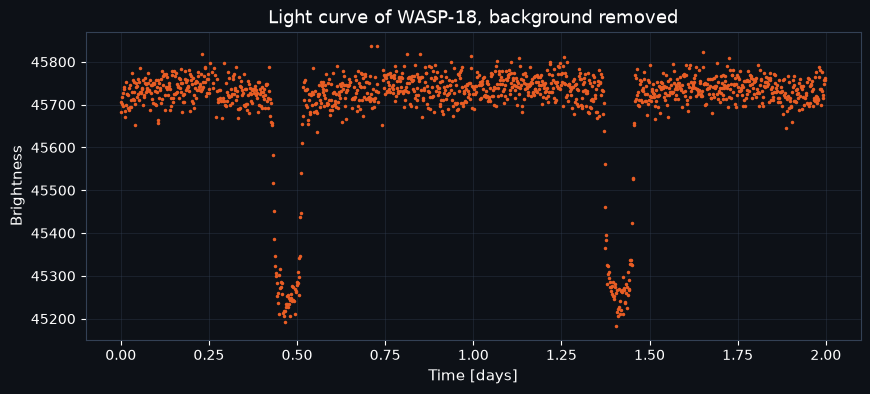

In [18]:
plot_light_curve(time, light_curve, title="Light curve of WASP-18, background removed")

**Prompts de profundización:**

- `¿Por qué la luz del fondo hace que un tránsito se vea menos profundo?`
- `¿Qué es la fotometría de apertura y cómo se resta el fondo del cielo?`

## 4. Normalizar por la mediana

El brillo normal de la estrella es la mediana de la curva:

In [19]:
print(np.median(light_curve))
print(np.median(light_curve[:170]))

nan
45737.367


Dividimos la curva por ese número: queda en "veces su brillo normal".

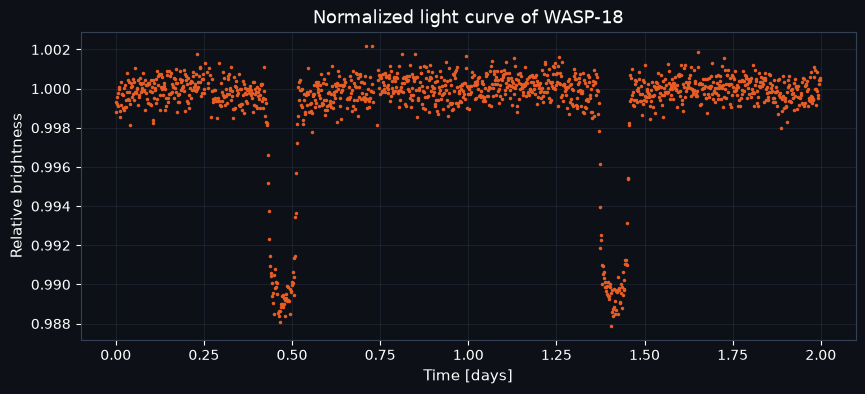

In [20]:
normalized = light_curve / np.median(light_curve[:170])

plot_light_curve(time, normalized, title="Normalized light curve of WASP-18", ylabel="Relative brightness")

**Prompts de profundización:**

- `¿Qué significa normalizar una serie de tiempo y para qué sirve?`
- `¿Por qué se normaliza una curva de luz por la mediana y no por el promedio?`
- `¿Cómo se pasa de la profundidad de un tránsito al tamaño del planeta?`

## 5. ¿Qué viene?

La curva ya está lista para medir el tránsito: ¿cuánto bajó, exactamente, la estrella?

In [21]:
print(np.min(normalized))

nan
